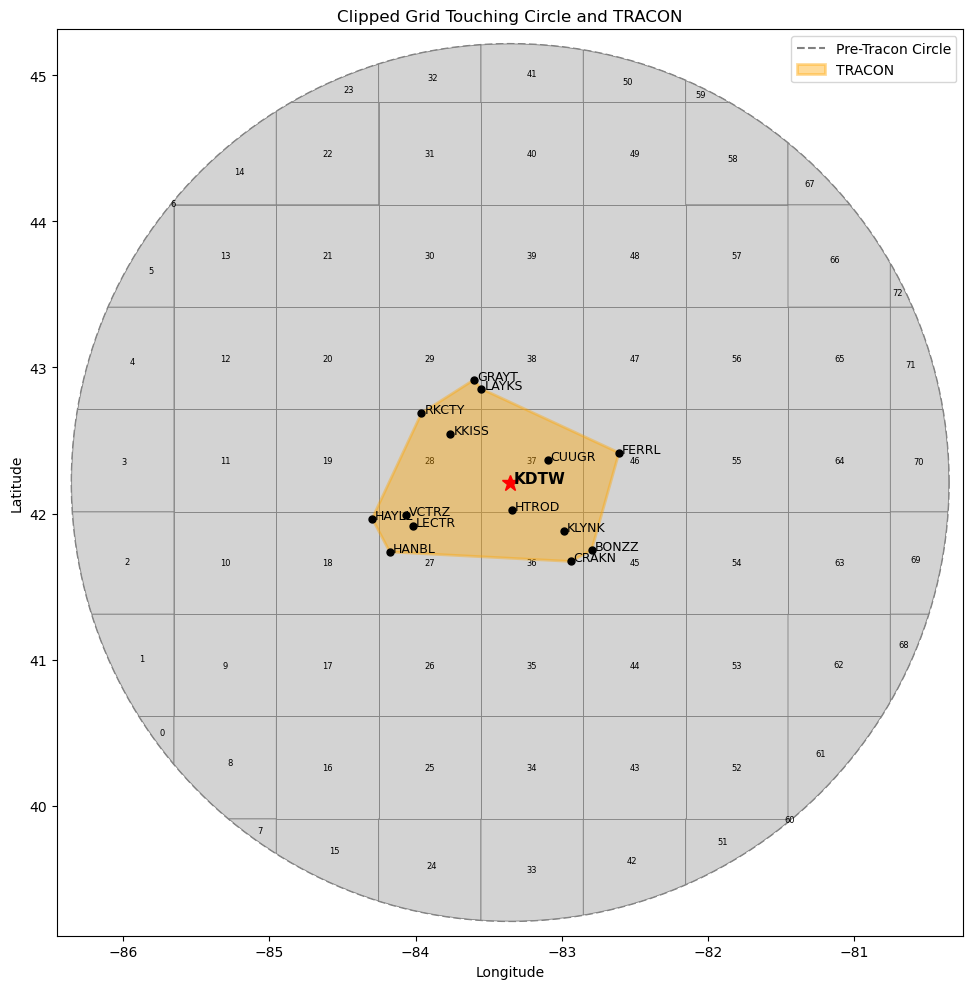

In [1]:
import matplotlib.pyplot as plt
from shapely.geometry import Polygon, box
from matplotlib.patches import Polygon as MplPolygon
import numpy as np

# === Constants ===
dtw_lat, dtw_lon = 42.2125, -83.3534
radius_deg = 3
grid_step = 0.7

# === STAR Fixes & TRACON Polygon ===
star_fixes = {
    "BONZZ": (-82.7972, 41.7483), "CRAKN": (-82.9405, 41.6730), "CUUGR": (-83.0975, 42.3643),
    "FERRL": (-82.6093, 42.4165), "GRAYT": (-83.6020, 42.9150), "HANBL": (-84.1773, 41.7375),
    "HAYLL": (-84.2975, 41.9662), "HTROD": (-83.3442, 42.0278), "KKISS": (-83.7620, 42.5443),
    "KLYNK": (-82.9888, 41.8793), "LAYKS": (-83.5498, 42.8532), "LECTR": (-84.0217, 41.9183),
    "RKCTY": (-83.9603, 42.6869), "VCTRZ": (-84.0670, 41.9878)
}
ordered_fix_names = ["CRAKN", "BONZZ", "FERRL", "LAYKS", "GRAYT", "RKCTY", "HAYLL", "HANBL"]
tracon_polygon = Polygon([star_fixes[name] for name in ordered_fix_names])

# === Pre-TRACON Circle Polygon ===
theta = np.linspace(0, 2 * np.pi, 400)
circle_coords = [(dtw_lon + radius_deg * np.cos(t), dtw_lat + radius_deg * np.sin(t)) for t in theta]
circle_polygon = Polygon(circle_coords)

# === Bounding box of circle ===
minx, miny, maxx, maxy = circle_polygon.bounds

# === Valid grid cells (intersect circle but not fully in tracon) ===
grid_cells = []
clipped_cells = []

for lon in np.arange(minx, maxx, grid_step):
    for lat in np.arange(miny, maxy, grid_step):
        cell = box(lon, lat, lon + grid_step, lat + grid_step)
        if circle_polygon.intersects(cell) and not tracon_polygon.contains(cell):
            clipped = cell.intersection(circle_polygon)
            if not clipped.is_empty:
                grid_cells.append(cell)
                clipped_cells.append(clipped)

# === Plot ===
fig, ax = plt.subplots(figsize=(10, 10))

# Outer Circle (full dashed boundary)
circle_x, circle_y = zip(*circle_coords)
ax.plot(circle_x, circle_y, linestyle='--', color='gray', linewidth=1.5, label='Pre-Tracon Circle', zorder=1)

# Clipped grid cells (gray boxes with labels)
for idx, poly in enumerate(clipped_cells):
    if isinstance(poly, Polygon):
        x, y = poly.exterior.xy
        ax.fill(x, y, facecolor='lightgray', edgecolor='gray', linewidth=0.6, zorder=2)
        cx, cy = poly.centroid.x, poly.centroid.y
        ax.text(cx, cy, str(idx), fontsize=6, ha='center', va='center', zorder=3)

# TRACON patch (on top)
tracon_patch = MplPolygon(tracon_polygon.exterior.coords, closed=True,
                          edgecolor='orange', facecolor='orange', alpha=0.4,
                          linewidth=2, label='TRACON', zorder=5)
ax.add_patch(tracon_patch)

# STAR fixes
for name, (lon, lat) in star_fixes.items():
    ax.plot(lon, lat, 'ko', markersize=5, zorder=6)
    ax.text(lon + 0.02, lat, name, fontsize=9, zorder=6)

# KDTW
ax.plot(dtw_lon, dtw_lat, 'r*', markersize=12, zorder=6)
ax.text(dtw_lon + 0.02, dtw_lat, 'KDTW', fontsize=11, fontweight='bold', zorder=6)

# Layout
ax.set_title("Clipped Grid Touching Circle and TRACON")
ax.set_aspect('equal')
ax.set_xlim(minx - 0.1, maxx + 0.1)
ax.set_ylim(miny - 0.1, maxy + 0.1)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend()
ax.grid(False)
plt.tight_layout()
plt.show()
